In [20]:
import os
os.chdir("C:/Users/Admin/Desktop/Mission_Ashi")
print("Working Directory:", os.getcwd())

Working Directory: C:\Users\Admin\Desktop\Mission_Ashi


In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from torch.utils.data import DataLoader, random_split
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import sys
sys.path.append('utils')
from dataset import BrainTumorDataset, get_class_names

In [22]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

np.random.seed(42)
torch.manual_seed(42)

print(" Setup complete!\n")

Device: cpu
 Setup complete!



In [23]:
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

print(" Transforms defined!\n")

 Transforms defined!



In [24]:
train_dir = './datasets/Multilabel_classification_dataset/Training'
test_dir = './datasets/Multilabel_classification_dataset/Testing'

full_train_dataset = BrainTumorDataset(train_dir, transform=transform_train)
test_dataset = BrainTumorDataset(test_dir, transform=transform_test)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

print(f"Train: {len(train_dataset)} images")
print(f"Validation: {len(val_dataset)} images")
print(f"Test: {len(test_dataset)} images\n")

Train: 4480 images
Validation: 1120 images
Test: 1600 images



In [25]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Get class names
class_names = get_class_names(train_dir)
print(f"Classes: {class_names}\n")

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']



In [26]:
model = models.mobilenet_v2(pretrained=True)

for param in model.features.parameters():
    param.requires_grad = False

model.classifier[1] = nn.Linear(model.last_channel, len(class_names))

model = model.to(device)

print(f" Model created!")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}\n")

C:\Users\Admin\Desktop\Mission_Ashi\venv_mission\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Admin\Desktop\Mission_Ashi\venv_mission\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


 Model created!
Total parameters: 2,228,996
Trainable parameters: 5,124



In [27]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

epochs = 10

history = {
    'train_loss': [],
    'val_loss': [],
    'val_acc': []
}

best_val_acc = 0.0

print(" Training setup complete!\n")

 Training setup complete!



In [28]:
print("="*60)
print("STARTING TRAINING")
print("="*60 + "\n")

for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")
    
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = train_loss / len(train_loader)
    history['train_loss'].append(avg_train_loss)

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    avg_val_loss = val_loss / len(val_loader)
    val_acc = val_correct / val_total
    
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)
    
    scheduler.step(avg_val_loss)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), './models/multiclass_model.pth')
        save_marker = "✅ BEST"
    else:
        save_marker = ""
    
    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f} | "
          f"Val Acc: {val_acc:.4f} {save_marker}")

print("\n" + "="*60)
print(f"TRAINING COMPLETE - Best Val Acc: {best_val_acc:.4f}")
print("="*60 + "\n")

model.load_state_dict(torch.load('./models/multiclass_model.pth'))
print(" Best model loaded!\n")

STARTING TRAINING



Epoch 1/10 [Train]: 100%|███████████████████████████████████████████████| 280/280 [04:46<00:00,  1.02s/it, loss=1.5570]


Epoch 1/10 | Train Loss: 0.6346 | Val Loss: 0.4549 | Val Acc: 0.8339 ✅ BEST


Epoch 2/10 [Train]: 100%|███████████████████████████████████████████████| 280/280 [05:30<00:00,  1.18s/it, loss=0.6959]


Epoch 2/10 | Train Loss: 0.4581 | Val Loss: 0.3678 | Val Acc: 0.8598 ✅ BEST


...

Epoch 8/10 | Train Loss: 0.3736 | Val Loss: 0.2638 | Val Acc: 0.9009 ✅ BEST


Epoch 9/10 [Train]: 100%|███████████████████████████████████████████████| 280/280 [03:55<00:00,  1.19it/s, loss=0.2417]


Epoch 9/10 | Train Loss: 0.3673 | Val Loss: 0.2821 | Val Acc: 0.8946 


Epoch 10/10 [Train]: 100%|██████████████████████████████████████████████| 280/280 [03:40<00:00,  1.27it/s, loss=0.6846]


Epoch 10/10 | Train Loss: 0.3816 | Val Loss: 0.2727 | Val Acc: 0.9009 

TRAINING COMPLETE - Best Val Acc: 0.9009

 Best model loaded!



In [29]:
model.eval()

all_preds = []
all_labels = []
all_probs = [] 

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)

print("="*60)
print("TEST SET EVALUATION")
print("="*60)
print(f"Test Accuracy: {test_acc:.4f}\n")

print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

TEST SET EVALUATION
Test Accuracy: 0.8419

Classification Report:
              precision    recall  f1-score   support

      glioma       0.91      0.70      0.79       400
  meningioma       0.71      0.79      0.75       400
     notumor       0.85      0.99      0.91       400
   pituitary       0.93      0.88      0.90       400

    accuracy                           0.84      1600
   macro avg       0.85      0.84      0.84      1600
weighted avg       0.85      0.84      0.84      1600



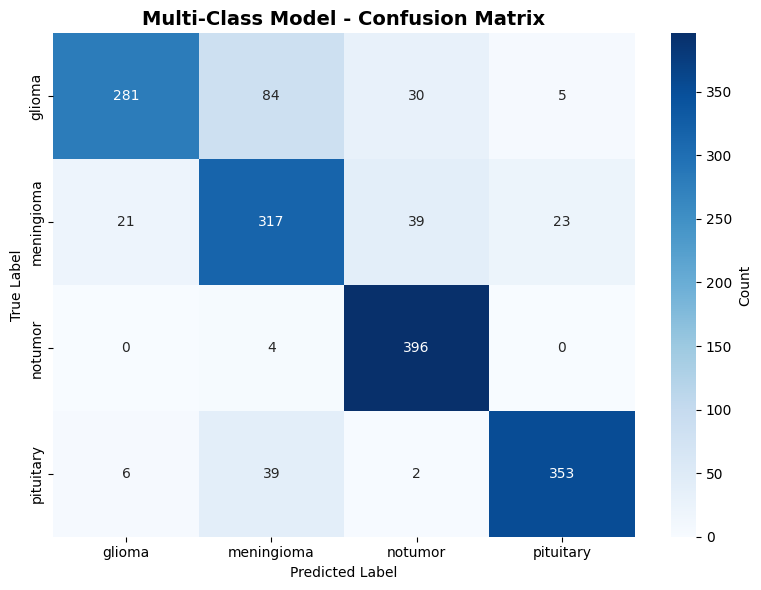

 Confusion matrix saved!



In [30]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.title('Multi-Class Model - Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('./notebooks/multiclass_cm.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Confusion matrix saved!\n")

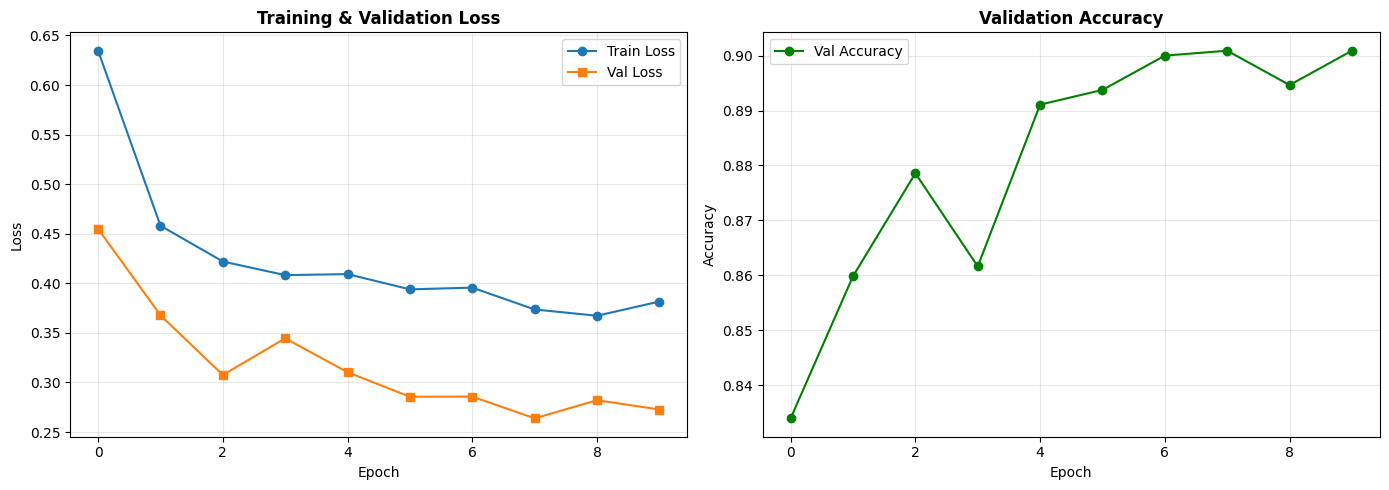

 Training history saved!



In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['train_loss'], label='Train Loss', marker='o')
ax1.plot(history['val_loss'], label='Val Loss', marker='s')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training & Validation Loss', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history['val_acc'], label='Val Accuracy', marker='o', color='green')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Validation Accuracy', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./notebooks/multiclass_training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Training history saved!\n")

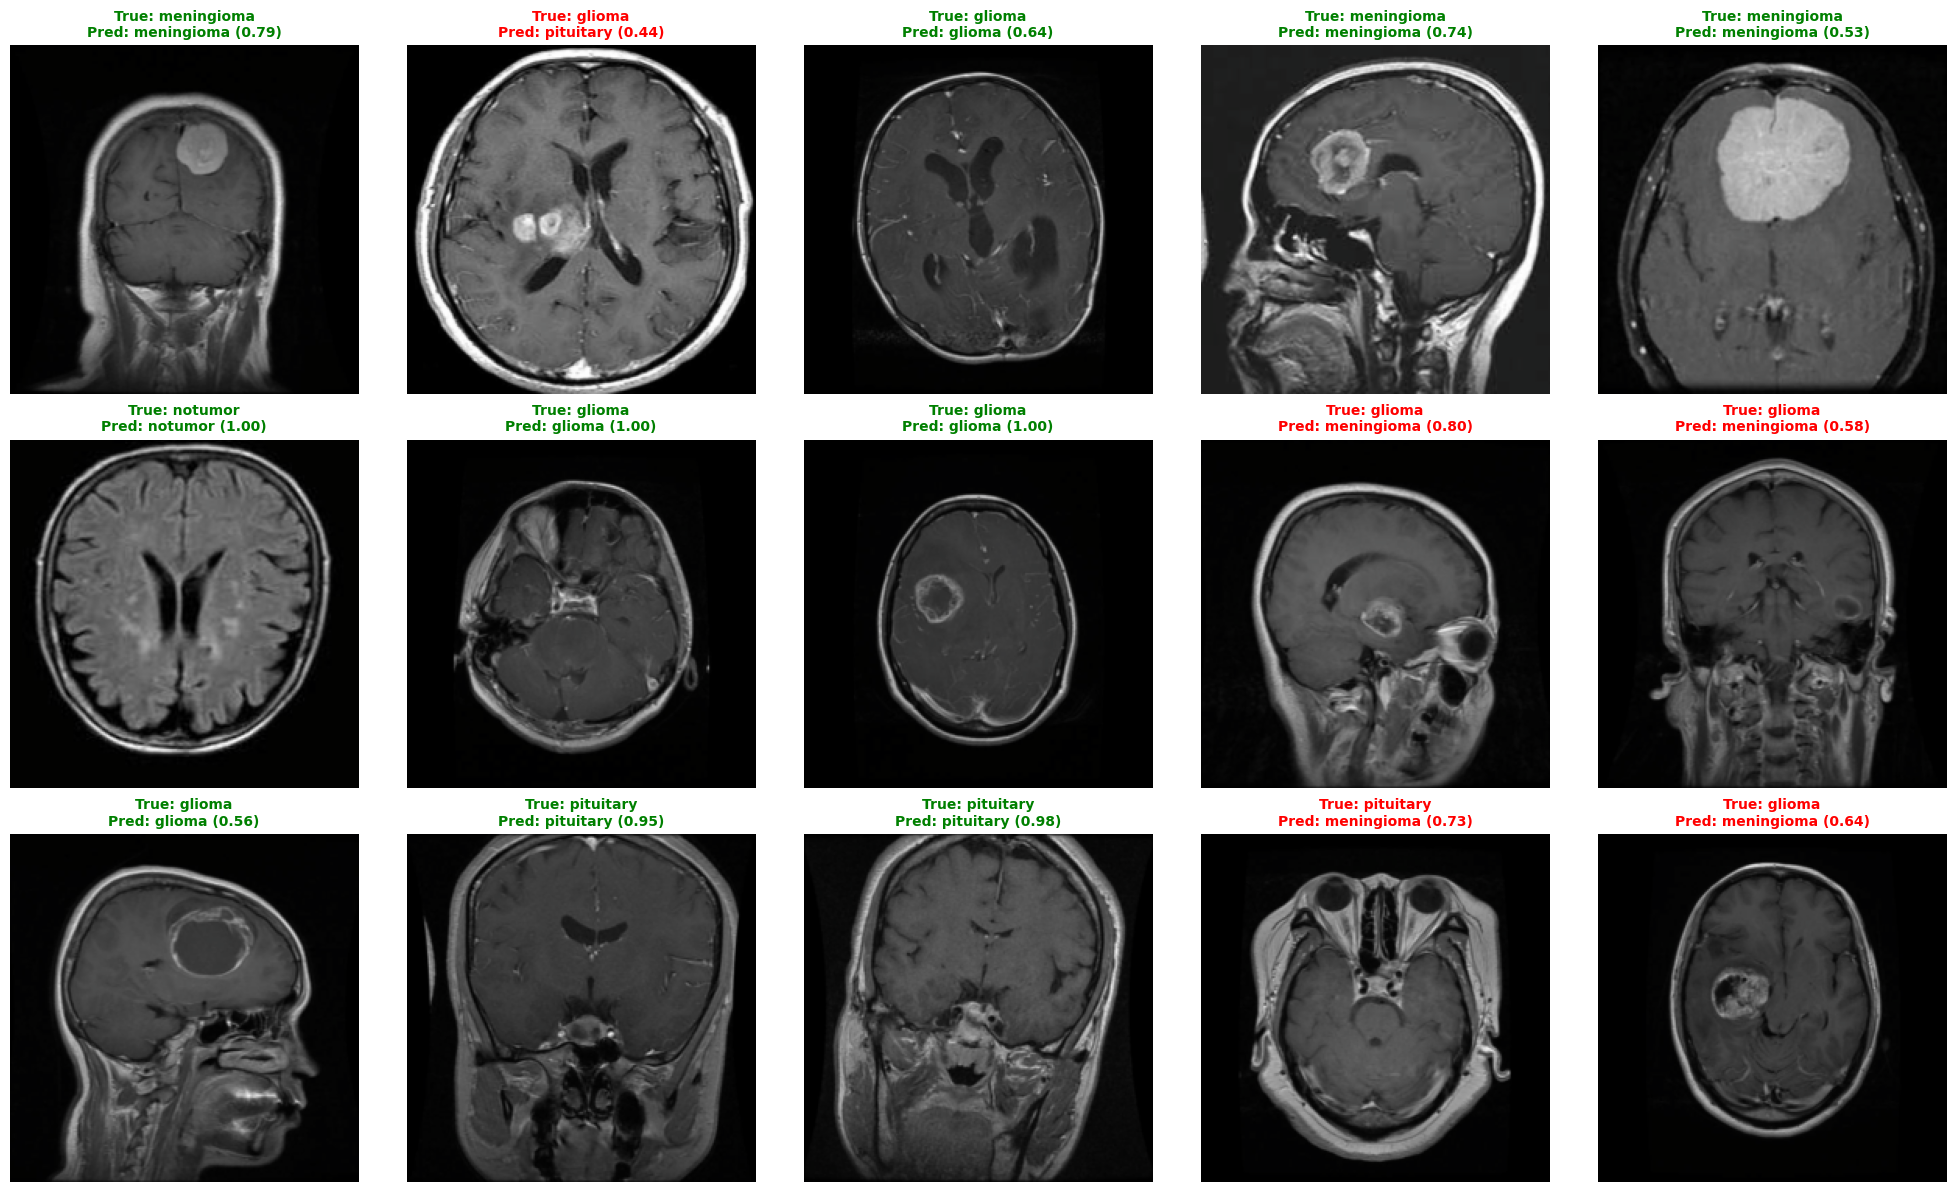

 Sample predictions saved!



In [32]:
import random

model.eval()

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()

sample_indices = random.sample(range(len(test_dataset)), 15)

for i, idx in enumerate(sample_indices):
    img_tensor, true_label = test_dataset[idx]
    
    with torch.no_grad():
        output = model(img_tensor.unsqueeze(0).to(device))
        probs = torch.softmax(output, dim=1)
        pred_label = torch.argmax(output, dim=1).item()
        confidence = probs[0][pred_label].item()
    
    img_display = img_tensor.permute(1, 2, 0).numpy()
    img_display = img_display * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img_display = np.clip(img_display, 0, 1)
    
    axes[i].imshow(img_display)
    
    color = 'green' if pred_label == true_label else 'red'
    axes[i].set_title(
        f'True: {class_names[true_label]}\n'
        f'Pred: {class_names[pred_label]} ({confidence:.2f})',
        color=color, fontweight='bold', fontsize=10
    )
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('./notebooks/multiclass_predictions.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Sample predictions saved!\n")

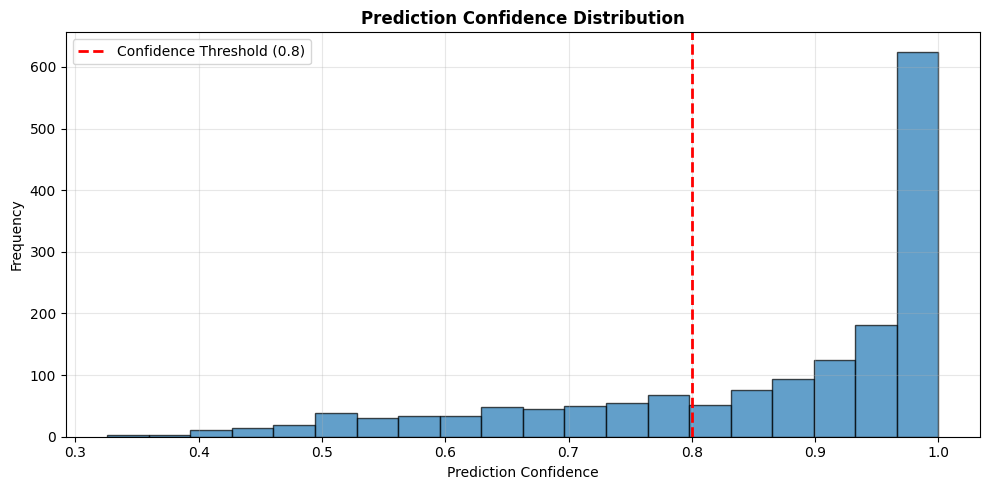

Low confidence predictions (<0.8): 453/1600 (28.3%)
 Confidence analysis complete!



In [33]:
all_probs_np = np.array(all_probs)
max_probs = np.max(all_probs_np, axis=1)

plt.figure(figsize=(10, 5))
plt.hist(max_probs, bins=20, edgecolor='black', alpha=0.7)
plt.axvline(x=0.8, color='red', linestyle='--', linewidth=2, label='Confidence Threshold (0.8)')
plt.xlabel('Prediction Confidence')
plt.ylabel('Frequency')
plt.title('Prediction Confidence Distribution', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('./notebooks/multiclass_confidence_dist.png', dpi=300, bbox_inches='tight')
plt.show()

low_confidence = sum(max_probs < 0.8)
print(f"Low confidence predictions (<0.8): {low_confidence}/{len(max_probs)} ({low_confidence/len(max_probs)*100:.1f}%)")
print(" Confidence analysis complete!\n")

In [34]:
import json

results = {
    'test_accuracy': float(test_acc),
    'best_val_accuracy': float(best_val_acc),
    'class_names': class_names,
    'total_params': sum(p.numel() for p in model.parameters()),
    'trainable_params': sum(p.numel() for p in model.parameters() if p.requires_grad),
    'epochs_trained': epochs
}

with open('./models/multiclass_results.json', 'w') as f:
    json.dump(results, f, indent=4)

print("="*60)
print("NOTEBOOK 1 COMPLETE!")
print("="*60)
print(f" Model saved: ./models/multiclass_model.pth")
print(f" Results saved: ./models/multiclass_results.json")
print(f" Test Accuracy: {test_acc:.4f}")
print("="*60)

NOTEBOOK 1 COMPLETE!
 Model saved: ./models/multiclass_model.pth
 Results saved: ./models/multiclass_results.json
 Test Accuracy: 0.8419
